# Diagnosing kernel geometry
These are exploratory, training-set diagnostics, not tests of quantum advantage.
Z, linear-entanglement ZZ, and all-to-all ZZ are implemented; there is no
separate IQP construction in this version.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/qkb").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from qkb.diagnostics import geometric_difference

## Geometric difference: no universal √n ceiling
[Huang et al. (2021), Eq. 5](https://www.nature.com/articles/s41467-021-22539-9)
defines $g(C\Vert Q)=\sqrt{\|Q^{1/2}C^{-1}Q^{1/2}\|_2}$ for trace-n kernels.
We report an explicitly ridge-stabilized variant $g_\lambda$ with
$C+\lambda I$ in the denominator. A symmetric generalized eigensolver avoids
explicitly taking a matrix inverse or square root.

The paper's full regularized error bound is not this simple ridge diagnostic.
For PSD kernels and λ > 0, $g_\lambda\le\sqrt{n/\lambda}$, not √n.
A nearly singular comparator can therefore produce large values. Large g
against one RBF comparator does not imply superior SVM accuracy or advantage
over the best classical model.

Analytical counterexample: n=2, g=31.622777; sqrt(n)=1.414214


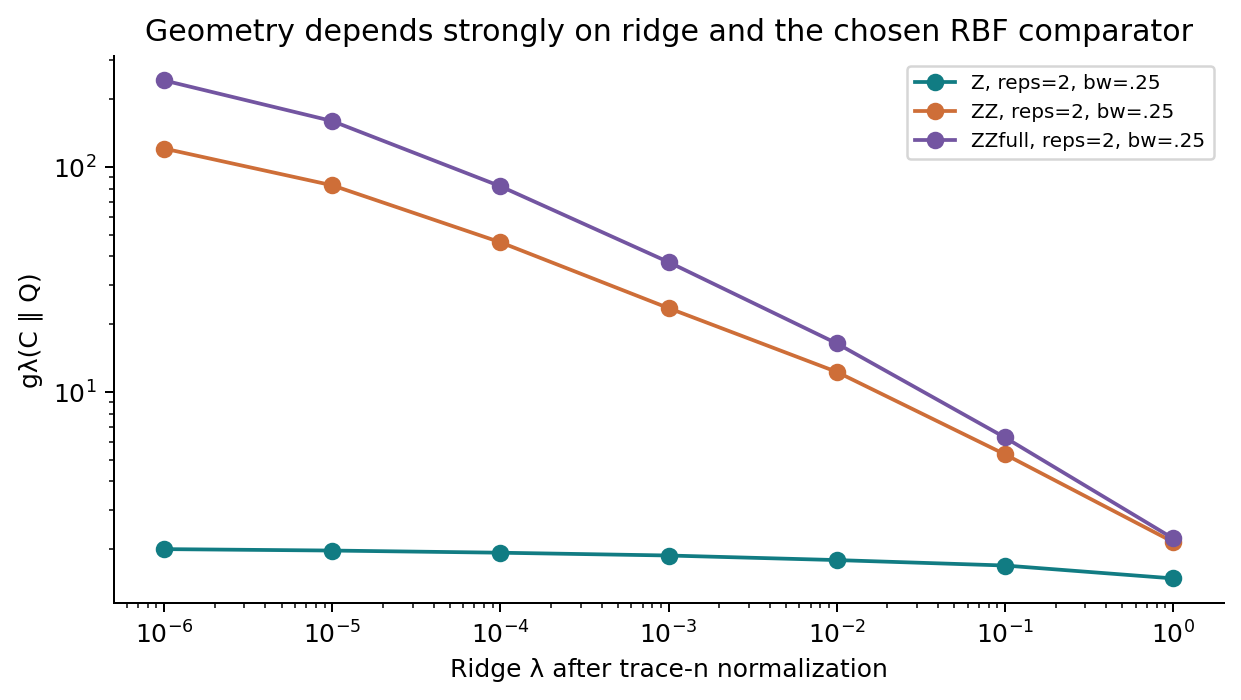

In [2]:
Q = np.eye(2)
C = np.ones((2, 2))
g = geometric_difference(Q, C, reg=1e-3)
print(f"Analytical counterexample: n=2, g={g:.6f}; sqrt(n)={np.sqrt(2):.6f}")
assert np.isclose(g, np.sqrt(1000))
display(Image(filename=str(ROOT / "figures/geometric_sensitivity.png")))

## Map, depth, and bandwidth
Every fixed-map curve tunes C inside inner CV. Selecting the largest curve
would reuse the outer folds for selection; only the nested benchmark estimates
the full map-selection procedure. Full-training alignment uses centered labels
and kernels and is descriptive. Off-diagonal variance alone does not diagnose
the cause of classification performance.

,fmap,reps,bandwidth,cv_acc,cv_std,inner_selection_acc,offdiag_mean,offdiag_var,alignment,geo_diff_ridge_0_001,ridge_complexity
0,Z,1,0.25,0.9640,0.0339,0.9732,0.8500,0.0151,0.4346,1.9476,18044.7527
8,Z,3,0.25,0.9639,0.0378,0.9642,0.6620,0.0390,0.5440,1.5427,12156.1518
4,Z,2,0.25,0.9522,0.0531,0.9644,0.8069,0.0229,0.3780,1.8747,14878.0271
5,Z,2,0.50,0.9522,0.0446,0.9554,0.4399,0.0700,0.4306,2.1376,7755.2017
1,Z,1,0.50,0.9493,0.0486,0.9642,0.5653,0.0656,0.4643,1.0830,12690.7012
9,Z,3,0.50,0.9340,0.0548,0.9289,0.4706,0.0403,0.4864,5.3374,6369.3391
2,Z,1,1.00,0.9283,0.0693,0.9379,0.2039,0.0578,0.4212,7.5181,6795.3212
6,Z,2,1.00,0.9136,0.0585,0.9109,0.2434,0.0508,0.5368,18.2117,1783.5713


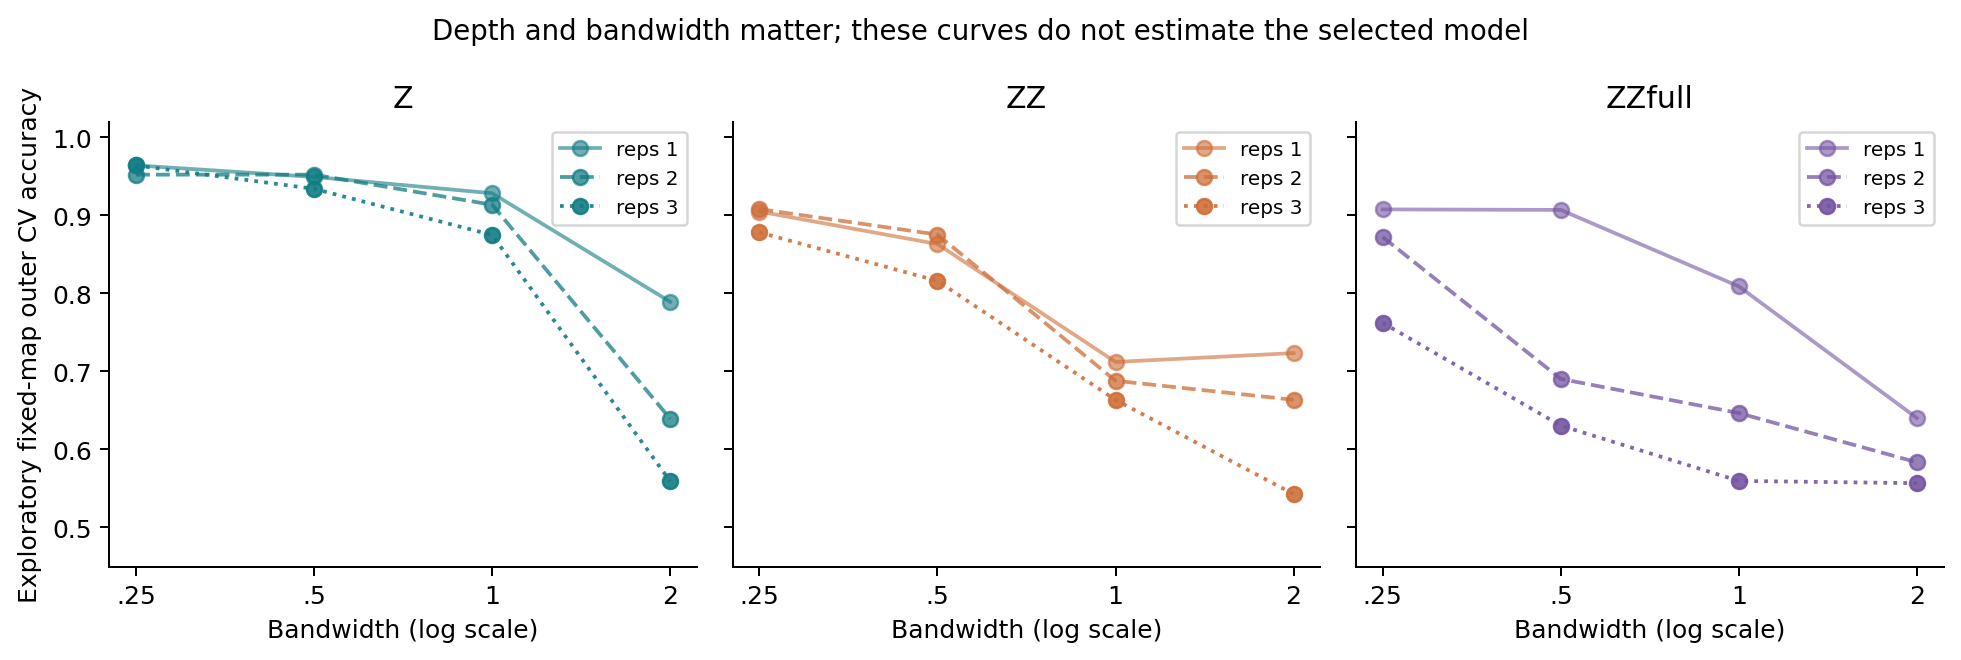

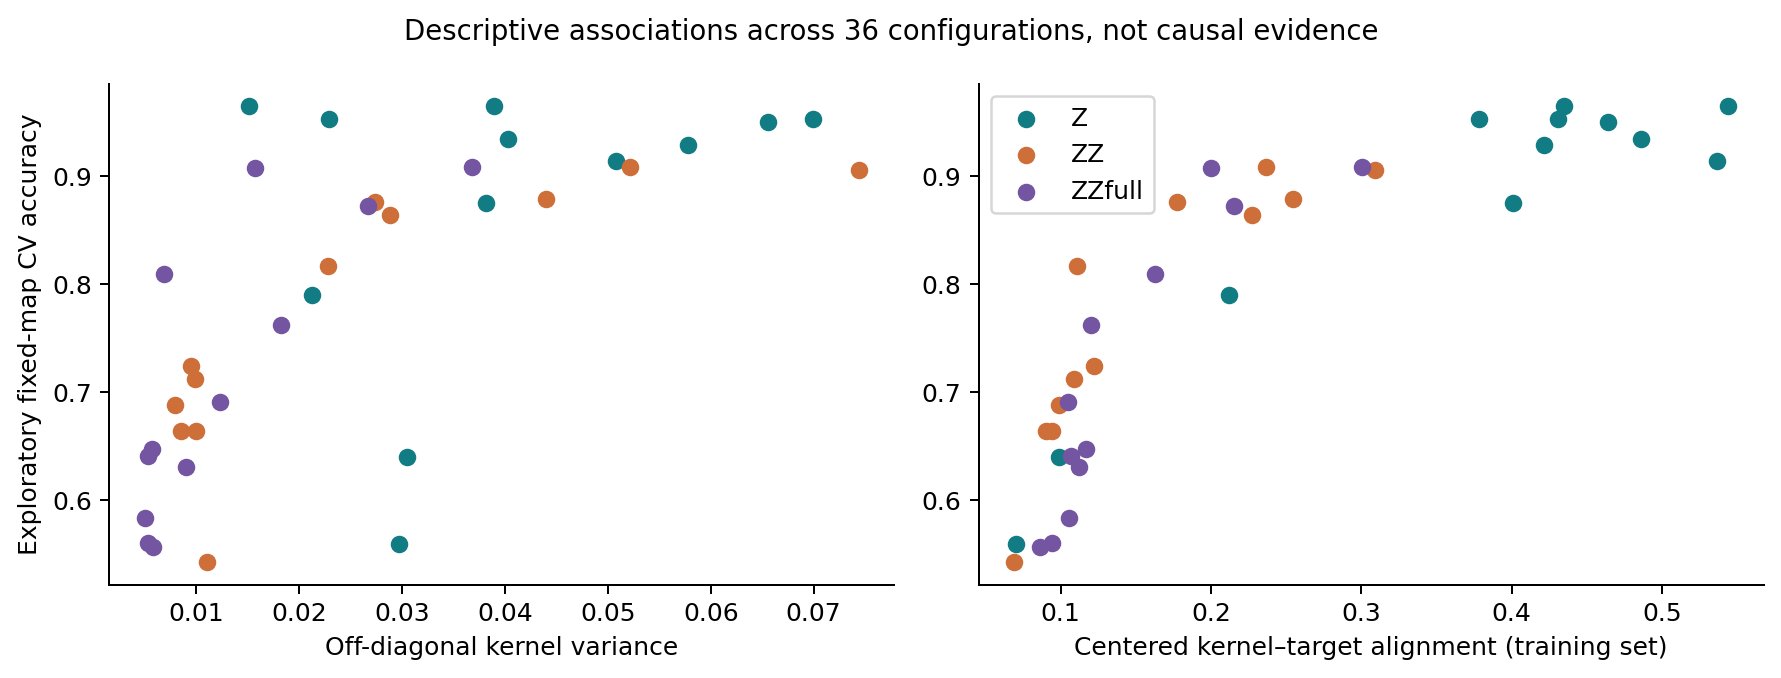

In [3]:
sweep = pd.read_csv(ROOT / "results/breast_cancer_4q/qkernel_sweep.csv")
display(sweep.sort_values("cv_acc", ascending=False).head(8).round(4))
display(Image(filename=str(ROOT / "figures/depth_bandwidth.png")))
display(Image(filename=str(ROOT / "figures/diagnostics.png")))

## Qubit sweep
This varies PCA dimensionality and qubit count together (2, 4, 6, 8) at reps=2.
It shows an association with representation size, not an isolated qubit effect.

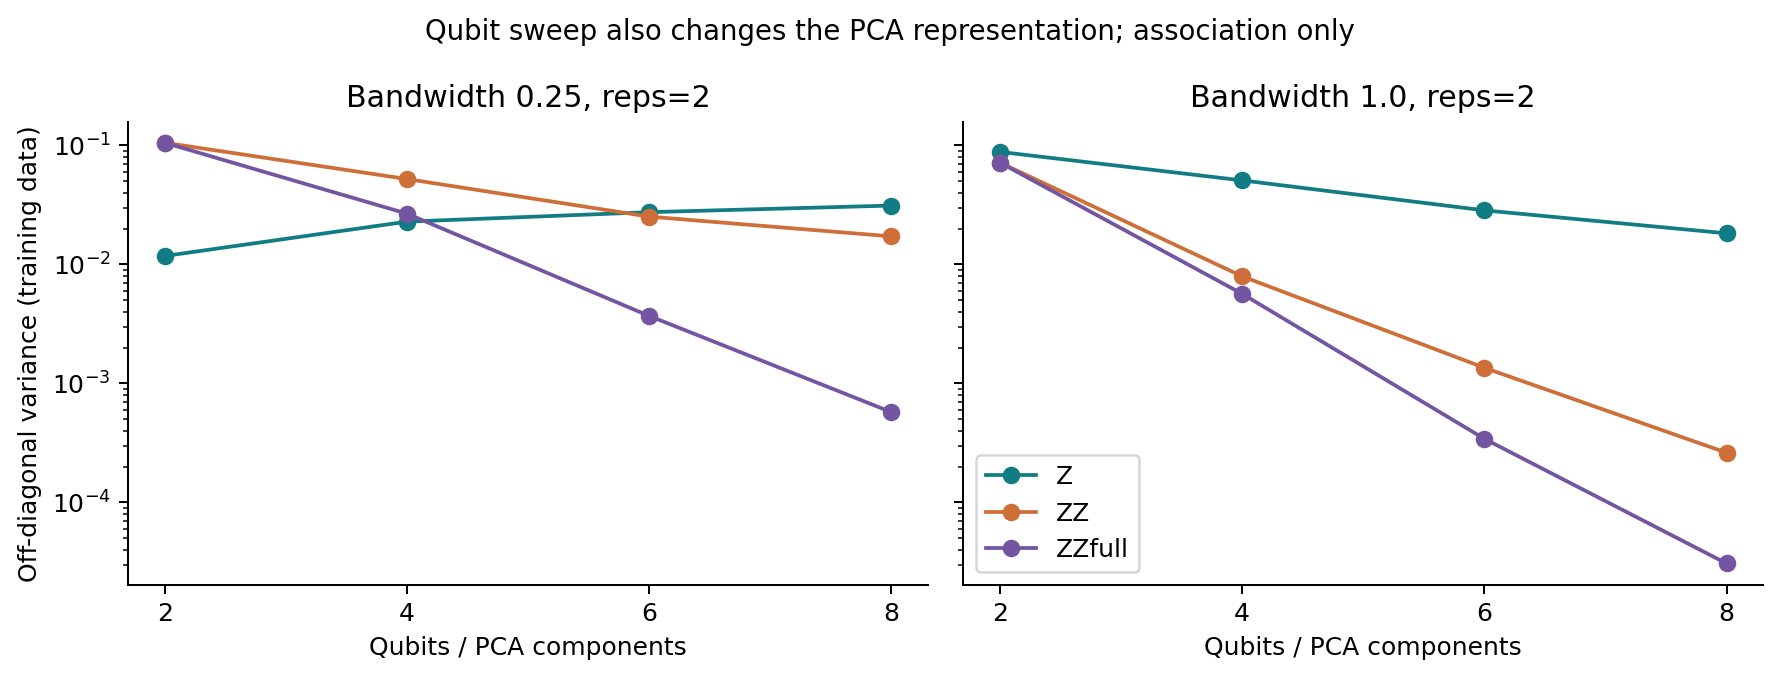

In [4]:
display(Image(filename=str(ROOT / "figures/concentration_qubits.png")))